# AWS cost estimator

Rough monthly cost of the AWS deployment in `infra/` and how long a block of credits lasts.
Change the **Parameters** cell, then *Run All*.

What it models (from `infra/envs/dev`): Claude on Bedrock describing each picture that has no alt text,
the pipeline Lambda, the website on ECS Express (Fargate task + load balancer + public IP),
S3, DynamoDB, ECR, CloudWatch, Cognito.

Prices are us-east-1 list prices as of late 2026. Set `REFRESH_PRICES_FROM_AWS = True` to pull the
Lambda, Fargate and load-balancer prices from the AWS Price List API instead. Bedrock prices are set by hand:
check them at https://aws.amazon.com/bedrock/pricing/.

In [1]:
# --- Parameters -------------------------------------------------------------
USERS                    = 100      # active users this month
FILES_PER_USER_PER_MONTH = 50       # slide decks each user submits per month (expected range 20-100)
PDF_SHARE                = 0.25     # share of those decks sent as a PDF export instead of .pptx
DECKS_PER_USER_PER_MONTH = FILES_PER_USER_PER_MONTH * (1 - PDF_SHARE)
PDFS_PER_USER_PER_MONTH  = FILES_PER_USER_PER_MONTH * PDF_SHARE
USER_GROWTH_PER_MONTH    = 0.0      # 0.05 = users grow 5% a month
CREDITS                  = 10_000   # USD of AWS credits

# What a deck looks like
IMAGES_PER_DECK          = 15       # pictures per deck that need a description (ones with alt text are skipped)
DECK_SIZE_MB             = 20       # average upload size

# A PDF here is a slide deck exported to PDF: one page per slide, the same pictures.
# PDFs are not processed on AWS yet (#147); this assumes the PDF pipeline runs in its own
# Lambda with Chrome and OCR and describes pictures with the same Bedrock model.
PAGES_PER_PDF            = 25
IMAGES_PER_PDF           = 15
SCANNED_PAGE_SHARE       = 0.05     # share of pages that need OCR (exports are mostly digital text)
PDF_SIZE_MB              = 8
PDF_LAMBDA_MEMORY_GB     = 4.0      # Chrome + OCR model
PDF_SECONDS_PER_PAGE     = 1.0      # digital page: extract, rebuild, print
OCR_SECONDS_PER_PAGE     = 4.0      # extra for a scanned page

# Bedrock (captioning). The deployed Lambda (aae-dev-pipeline) uses Claude Haiku 4.5 through the
# us. inference profile, set in terraform.tfvars. Prices from the AWS Price List (Nov 2026):
#   Haiku 4.5   us. profile $1.10 / $5.50   global profile $1.00 / $5.00
#   Haiku 5.5   regional    $0.11 / $0.55   Opus 5 (the variables.tf default) $5.50 / $27.50
BEDROCK_INPUT_PER_MTOK   = 1.10     # USD per million input tokens
BEDROCK_OUTPUT_PER_MTOK  = 5.50     # USD per million output tokens
INPUT_TOKENS_PER_IMAGE   = 1_500    # ~1,050 for a 1024px image (MAX_IMAGE_DIMENSION) + prompt and slide text
OUTPUT_TOKENS_PER_IMAGE  = 150      # a one- or two-sentence description; Haiku 4.5 does not think unless asked
CREDITS_COVER_BEDROCK    = True     # Claude on Bedrock is billed as AWS Marketplace usage, which many credit programs exclude

# Lambda (var.lambda_memory_mb, var.lambda_architecture)
LAMBDA_MEMORY_GB         = 2.0
LAMBDA_BASE_SECONDS      = 10       # open, reorder, check, save one deck
LAMBDA_SECONDS_PER_IMAGE = 3        # waiting on Bedrock per picture
LAMBDA_FREE_TIER         = True     # 400k GB-s and 1M requests free each month

# Website (var.web_cpu / web_memory / web_min_tasks)
WEB_TASKS                = 1
WEB_VCPU                 = 0.25
WEB_MEMORY_GB            = 0.5

# Storage and retention (s3_buckets expiration_days)
RETENTION_DAYS           = 30       # how long uploads and processed files stay in S3
LOG_RETENTION_DAYS       = 30

PROJECTION_MONTHS        = 36       # how far the burn-down chart looks ahead
REFRESH_PRICES_FROM_AWS  = False    # needs AWS credentials with pricing:GetProducts


## Unit prices

In [2]:
HOURS = 730  # hours in a month

PRICE = {
    'lambda_gb_s':      0.0000166667,  # x86_64; arm64 is 0.0000133334
    'lambda_request':   0.20 / 1e6,
    'fargate_vcpu_hr':  0.04048,
    'fargate_gb_hr':    0.004445,
    'alb_hr':           0.0225,        # ECS Express provisions an ALB
    'alb_lcu_hr':       0.008,
    'public_ipv4_hr':   0.005,
    's3_gb_month':      0.023,
    's3_put':           0.005 / 1000,
    's3_get':           0.0004 / 1000,
    'ddb_write':        0.625 / 1e6,   # on-demand write request unit
    'ddb_read':         0.125 / 1e6,
    'ecr_gb_month':     0.10,
    'logs_ingest_gb':   0.50,
    'logs_store_gb':    0.03,
    'alarm':            0.10,
    'cognito_mau':      0.015,         # Essentials tier, after 10k free MAU
    'ssm_secrets':      0.0,           # standard parameters are free
}

if REFRESH_PRICES_FROM_AWS:
    import json, boto3
    pricing = boto3.client('pricing', region_name='us-east-1')

    def list_price(service, **filters):
        f = [{'Type': 'TERM_MATCH', 'Field': k, 'Value': v} for k, v in filters.items()]
        product = json.loads(pricing.get_products(ServiceCode=service, Filters=f, MaxResults=1)['PriceList'][0])
        term = next(iter(product['terms']['OnDemand'].values()))
        return float(next(iter(term['priceDimensions'].values()))['pricePerUnit']['USD'])

    lookups = {
        'lambda_gb_s':     ('AWSLambda', {'usagetype': 'USE1-Lambda-GB-Second', 'regionCode': 'us-east-1'}),
        'fargate_vcpu_hr': ('AmazonECS', {'usagetype': 'USE1-Fargate-vCPU-Hours:perCPU', 'regionCode': 'us-east-1'}),
        'fargate_gb_hr':   ('AmazonECS', {'usagetype': 'USE1-Fargate-GB-Hours', 'regionCode': 'us-east-1'}),
        'alb_hr':          ('AmazonEC2', {'usagetype': 'USE1-LoadBalancerUsage', 'productFamily': 'Load Balancer-Application'}),
    }
    for key, (service, filters) in lookups.items():
        try:
            new = list_price(service, **filters)
            print(f'{key:16} {PRICE[key]:.10g} -> {new:.10g}')
            PRICE[key] = new
        except Exception as e:  # keep the default rather than stop the notebook
            print(f'{key:16} kept default ({type(e).__name__}: {e})')


## Cost model

In [3]:
def monthly_cost(users, decks_per_user=None, pdfs_per_user=None, images_per_deck=None):
    """USD for one month, by category."""
    decks_per_user = DECKS_PER_USER_PER_MONTH if decks_per_user is None else decks_per_user
    pdfs_per_user = PDFS_PER_USER_PER_MONTH if pdfs_per_user is None else pdfs_per_user
    images_per_deck = IMAGES_PER_DECK if images_per_deck is None else images_per_deck
    pdfs = users * pdfs_per_user
    decks = users * decks_per_user
    images = decks * images_per_deck + pdfs * IMAGES_PER_PDF

    bedrock = images * (INPUT_TOKENS_PER_IMAGE * BEDROCK_INPUT_PER_MTOK
                        + OUTPUT_TOKENS_PER_IMAGE * BEDROCK_OUTPUT_PER_MTOK) / 1e6

    gb_s = decks * (LAMBDA_BASE_SECONDS + LAMBDA_SECONDS_PER_IMAGE * images_per_deck) * LAMBDA_MEMORY_GB
    gb_s += pdfs * (LAMBDA_BASE_SECONDS + PAGES_PER_PDF * (PDF_SECONDS_PER_PAGE + SCANNED_PAGE_SHARE * OCR_SECONDS_PER_PAGE)
                    + LAMBDA_SECONDS_PER_IMAGE * IMAGES_PER_PDF) * PDF_LAMBDA_MEMORY_GB
    free_gb_s, free_req = (400_000, 1_000_000) if LAMBDA_FREE_TIER else (0, 0)
    lam = max(0, gb_s - free_gb_s) * PRICE['lambda_gb_s'] + max(0, decks + pdfs - free_req) * PRICE['lambda_request']

    web = WEB_TASKS * HOURS * (WEB_VCPU * PRICE['fargate_vcpu_hr'] + WEB_MEMORY_GB * PRICE['fargate_gb_hr'] + PRICE['public_ipv4_hr'])
    web += HOURS * (PRICE['alb_hr'] + PRICE['alb_lcu_hr'])  # ponytail: assumes <1 LCU, true for a few thousand users

    # original + fixed file kept for RETENTION_DAYS; ~3 puts and ~10 gets per file
    files = decks + pdfs
    s3_gb = (decks * DECK_SIZE_MB + pdfs * PDF_SIZE_MB) * 2 / 1024 * RETENTION_DAYS / 30
    storage = (s3_gb * PRICE['s3_gb_month'] + files * (3 * PRICE['s3_put'] + 10 * PRICE['s3_get'])
               + files * (30 * PRICE['ddb_write'] + 100 * PRICE['ddb_read'])  # progress updates, status polling
               + 3 * PRICE['ecr_gb_month'])  # two images, ~3 GB

    log_gb = files * 0.2 / 1024  # ~200 KB of logs per file
    other = (log_gb * PRICE['logs_ingest_gb'] + log_gb * LOG_RETENTION_DAYS / 30 * PRICE['logs_store_gb']
             + 4 * PRICE['alarm'] + max(0, users - 10_000) * PRICE['cognito_mau'])

    return {'Bedrock (descriptions)': bedrock, 'Lambda': lam, 'Website (Fargate + ALB)': web,
            'Storage (S3, DynamoDB, ECR)': storage, 'Logs, alarms, Cognito': other}


def credit_cost(costs):
    """The part of a month's bill that credits pay for."""
    return sum(v for k, v in costs.items() if CREDITS_COVER_BEDROCK or not k.startswith('Bedrock'))


def projection(users=USERS, decks_per_user=None, months=PROJECTION_MONTHS, growth=USER_GROWTH_PER_MONTH, pdfs_per_user=None):
    """Credits left at the end of each month, and the month they run out (None if they outlast `months`)."""
    left, remaining, runout = CREDITS, [], None
    for m in range(months):
        left -= credit_cost(monthly_cost(users * (1 + growth) ** m, decks_per_user, pdfs_per_user))
        remaining.append(left)
        if left <= 0 and runout is None:
            runout = m + 1
    return remaining, runout


costs = monthly_cost(USERS)
total = sum(costs.values())
remaining, runout = projection()
decks = USERS * DECKS_PER_USER_PER_MONTH
files = decks + USERS * PDFS_PER_USER_PER_MONTH

for k, v in costs.items():
    print(f'{k:30} ${v:>10,.2f}')
print(f'{"Total per month":30} ${total:>10,.2f}')
print(f'\n{files:,.0f} files/month -> ${total / max(files, 1):.3f} per file, ${costs["Bedrock (descriptions)"] / max(files, 1):.3f} of it Bedrock')
if not CREDITS_COVER_BEDROCK:
    print(f'Paid out of pocket (Bedrock): ${costs["Bedrock (descriptions)"]:,.2f}/month')
print(f'${CREDITS:,} of credits last ' + (f'{runout} months' if runout else f'more than {PROJECTION_MONTHS} months')
      + (f' at {USER_GROWTH_PER_MONTH:.0%} user growth a month' if USER_GROWTH_PER_MONTH else ' at flat usage'))


Bedrock (descriptions)         $    185.62
Lambda                         $      7.29
Website (Fargate + ALB)        $     34.93
Storage (S3, DynamoDB, ECR)    $      4.37
Logs, alarms, Cognito          $      0.92
Total per month                $    233.13

5,000 files/month -> $0.047 per file, $0.037 of it Bedrock
$10,000 of credits last more than 36 months at flat usage


## Charts

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)  # Open Sans (UW's font) is optional

# UW brand colours
PURPLE, GOLD, SPIRIT_GOLD, HERITAGE_GOLD, LAVENDER, GRAY = '#4B2E83', '#B7A57A', '#FFC700', '#85754D', '#C5B4E3', '#D9D9D9'
MID_PURPLE, DARK_GRAY = '#7D64B0', '#5A5A5A'
# every series colour is at least 3:1 against white (WCAG 1.4.11); light gold and lavender are kept for fills only
UW_SERIES = [PURPLE, HERITAGE_GOLD, MID_PURPLE, DARK_GRAY, GOLD]

plt.rcParams.update({
    'font.family': ['Open Sans', 'Segoe UI', 'DejaVu Sans'],
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#555', 'axes.titleweight': 'bold', 'axes.titlecolor': PURPLE,
    'axes.titlesize': 13, 'axes.titlelocation': 'left',
})
money = plt.FuncFormatter(lambda x, _: f'${x:,.0f}')

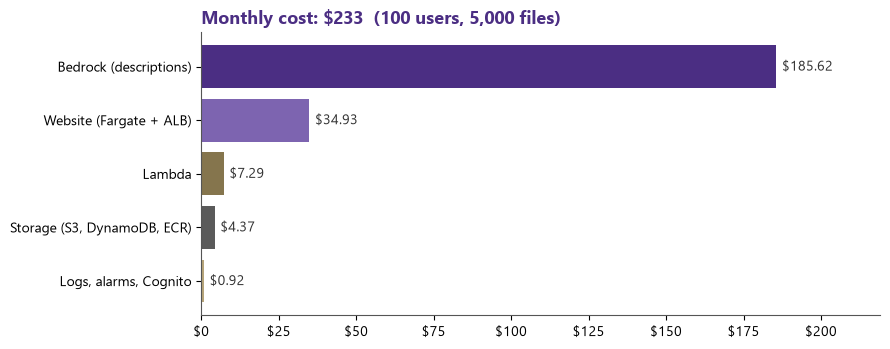

In [5]:
# 1. Where the money goes this month
fig, ax = plt.subplots(figsize=(9, 3.6))
items = sorted(costs.items(), key=lambda kv: kv[1])
bars = ax.barh([k for k, _ in items], [v for _, v in items],
               color=[UW_SERIES[list(costs).index(k)] for k, _ in items])
ax.bar_label(bars, labels=[f'${v:,.2f}' for _, v in items], padding=4, color='#333')
ax.xaxis.set_major_formatter(money)
ax.set_title(f'Monthly cost: ${total:,.0f}  ({USERS} users, {files:,.0f} files)')
ax.margins(x=0.18)
plt.tight_layout(); plt.show()

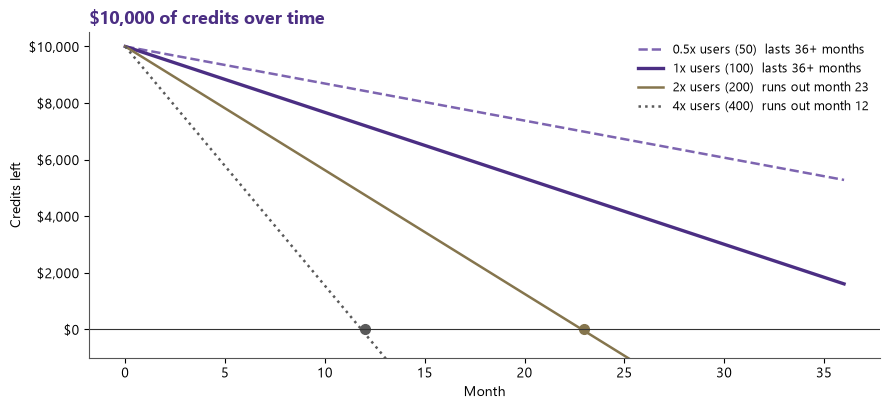

In [6]:
# 2. Credit burn-down for lighter and heavier usage than the parameters
fig, ax = plt.subplots(figsize=(9, 4.2))
months = np.arange(0, PROJECTION_MONTHS + 1)
for mult, colour, style in [(0.5, MID_PURPLE, '--'), (1, PURPLE, '-'), (2, HERITAGE_GOLD, '-'), (4, DARK_GRAY, ':')]:
    rem, out = projection(users=USERS * mult)
    label = f'{mult:g}x users ({USERS * mult:g})  ' + (f'runs out month {out}' if out else f'lasts {PROJECTION_MONTHS}+ months')
    ax.plot(months, [CREDITS] + rem, style, color=colour, lw=2.4 if mult == 1 else 1.8, label=label)
    if out:
        ax.plot(out, 0, 'o', color=colour, ms=7)
ax.axhline(0, color='#333', lw=0.8)
ax.set_ylim(-CREDITS * 0.1, CREDITS * 1.05)
ax.yaxis.set_major_formatter(money)
ax.set_xlabel('Month'); ax.set_ylabel('Credits left')
ax.set_title(f'${CREDITS:,} of credits over time' + (f', users +{USER_GROWTH_PER_MONTH:.0%}/month' if USER_GROWTH_PER_MONTH else ''))
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

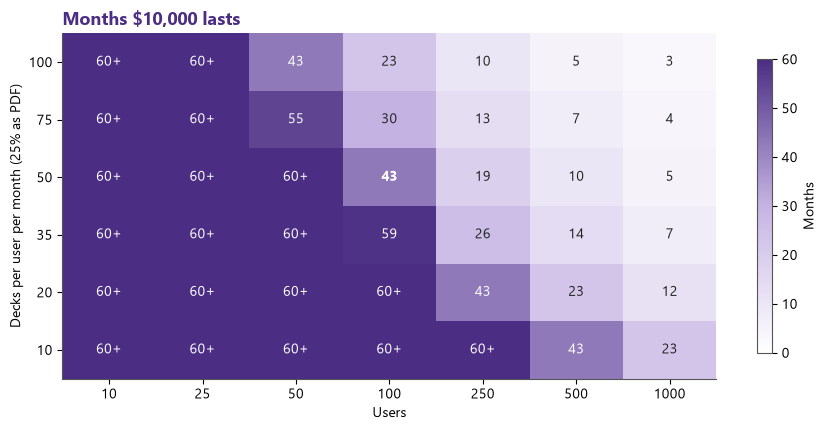

In [7]:
# 3. Months of runway for any mix of users and decks per user
user_grid = [10, 25, 50, 100, 250, 500, 1000]
deck_grid = [10, 20, 35, 50, 75, 100]
runway = np.array([[projection(u, d * (1 - PDF_SHARE), months=60, pdfs_per_user=d * PDF_SHARE)[1] or 60 for u in user_grid] for d in deck_grid])

fig, ax = plt.subplots(figsize=(9, 4.4))
cmap = LinearSegmentedColormap.from_list('uw', ['#FFFFFF', LAVENDER, PURPLE])
im = ax.imshow(runway, cmap=cmap, vmin=0, vmax=60, aspect='auto', origin='lower')
for i in range(len(deck_grid)):
    for j in range(len(user_grid)):
        v = runway[i, j]
        ax.text(j, i, '60+' if v >= 60 else v, ha='center', va='center',
                color='white' if v > 35 else '#222', fontsize=10, fontweight='bold' if (user_grid[j], deck_grid[i]) == (USERS, FILES_PER_USER_PER_MONTH) else 'normal')
ax.set_xticks(range(len(user_grid)), user_grid); ax.set_yticks(range(len(deck_grid)), deck_grid)
ax.set_xlabel('Users'); ax.set_ylabel(f'Decks per user per month ({PDF_SHARE:.0%} as PDF)')
ax.set_title(f'Months ${CREDITS:,} lasts' + (f' (users +{USER_GROWTH_PER_MONTH:.0%}/month)' if USER_GROWTH_PER_MONTH else ''))
fig.colorbar(im, ax=ax, label='Months', shrink=0.85)
plt.tight_layout(); plt.show()

## Optional: compare with what AWS actually billed

Cost Explorer has the real spend once the stack has been running. Each API call costs $0.01.
The same numbers from a terminal:

```powershell
aws ce get-cost-and-usage --time-period Start=2026-10-01,End=2026-11-01 --granularity MONTHLY --metrics UnblendedCost --group-by Type=DIMENSION,Key=SERVICE
aws ce get-cost-forecast --time-period Start=2026-11-21,End=2026-12-31 --granularity MONTHLY --metric UNBLENDED_COST
aws pricing get-products --service-code AWSLambda --region us-east-1 --filters Type=TERM_MATCH,Field=usagetype,Value=USE1-Lambda-GB-Second --max-results 1
```

The [AWS Pricing Calculator](https://calculator.aws/) is the GUI version of this notebook if you need a quote to share.

In [8]:
SHOW_ACTUAL_SPEND = False  # needs ce:GetCostAndUsage

if SHOW_ACTUAL_SPEND:
    import datetime as dt, boto3, pandas as pd
    end = dt.date.today().replace(day=1)
    start = (end - dt.timedelta(days=90)).replace(day=1)
    resp = boto3.client('ce', region_name='us-east-1').get_cost_and_usage(
        TimePeriod={'Start': str(start), 'End': str(end)}, Granularity='MONTHLY',
        Metrics=['UnblendedCost'], GroupBy=[{'Type': 'DIMENSION', 'Key': 'SERVICE'}],
        Filter={'Not': {'Dimensions': {'Key': 'RECORD_TYPE', 'Values': ['Credit']}}})  # usage before credits
    rows = [(r['TimePeriod']['Start'], g['Keys'][0], float(g['Metrics']['UnblendedCost']['Amount']))
            for r in resp['ResultsByTime'] for g in r['Groups']]
    actual = pd.DataFrame(rows, columns=['month', 'service', 'usd']).pivot_table(index='service', columns='month', values='usd', fill_value=0)
    display(actual[actual.sum(axis=1) > 0.01].round(2).sort_values(actual.columns[-1], ascending=False))